
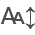

In [6]:
import streamlit as st
import pandas as pd
import datetime
from bs4 import BeautifulSoup
import base64
import requests
import pandas as pd
import webbrowser
import warnings
import datetime
from datetime import datetime as dt
from datetime import timedelta
import datetime
import numpy as np
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objs as go
import plotly.offline as py
import plotly
#import qgrid
import itable
import pandasql as sqldf
from pandasql import sqldf
from st_aggrid import AgGrid, GridOptionsBuilder
from itables import to_html_datatable
from streamlit.components.v1 import html
import itables.options as opt
from itables import init_notebook_mode
import pygwalker as pyg
from pygwalker.api.streamlit import StreamlitRenderer
init_notebook_mode(all_interactive=True)
import teradata
import indices_performance as pfm
from datetime import datetime, timedelta

In [7]:

# Conexões 
producao_url = 'https://api.anbima.com.br/'
sandbox_url = 'https://api-sandbox.anbima.com.br/'
id_url = "https://api.anbima.com.br/oauth/access-token"
id_url = 'https://api.anbima.com.br/access-token'
### Define se dados vem de ambiente de producao ou sandbox ###

# Conexões 
producao_url = 'https://api.anbima.com.br/'
sandbox_url = 'https://api-sandbox.anbima.com.br/'
id_url = "https://api.anbima.com.br/oauth/access-token"
id_url_sandbox = "https://api-sandbox.anbima.com.br/oauth/access-token"

### Define se dados vem de ambiente de producao ou sandbox ###
producao = True

if producao:
  url = producao_url
  client_id = "wRGlvlj1bOW3"
  client_secret = "l4riAuRd0CUL"
  client_credentials = "wRGlvlj1bOW3:l4riAuRd0CUL"

else:
  url = sandbox_url
  client_id = "nZqmOGEuh6bg"
  client_secret = "BMXhChrji7ca"
  client_credentials = "nZqmOGEuh6bg:BMXhChrji7ca"


client_credentials = client_credentials.encode('ascii')
senhabytes = base64.b64encode(client_credentials)
senha = base64.b64decode(senhabytes)

def conectar(client_id, client_secret, client_credentials, url=url, id_url=id_url):
    client_credentials = client_credentials.encode('ascii')
    senhabytes = base64.b64encode(client_credentials)
    senha = base64.b64decode(senhabytes)
    senha_txt = senhabytes.decode('utf-8')
    body = {"grant_type": "client_credentials" }

    headers = {
            'content-type': 'application/json',
            'Authorization': 'Basic ' + senha_txt}
    
    
    request = requests.post(id_url, headers=headers, json=body, allow_redirects=True)
    informacoes = request.json()
    token = informacoes['access_token']  
    
    return { "content-type": "application/json",
            "client_id": f"{client_id}",
            "access_token": f"{token}"}
   

####  Header produção###
#headers = conectar('wRGlvlj1bOW3', 'l4riAuRd0CUL','wRGlvlj1bOW3:l4riAuRd0CUL', url)
headers = conectar('wRGlvlj1bOW3', 'l4riAuRd0CUL','wRGlvlj1bOW3:l4riAuRd0CUL', url, id_url)

### Header Sandbox ###   
#headers2 = conectar('nZqmOGEuh6bg', 'BMXhChrji7ca','nZqmOGEuh6bg:BMXhChrji7ca', url)
headers2 = conectar('nZqmOGEuh6bg', 'BMXhChrji7ca','nZqmOGEuh6bg:BMXhChrji7ca', url, id_url)


def extrair_json(http, headers = headers):
    request = requests.get(http, headers=headers)
    try:
        df = request.json()
        return df
    except ValueError:
        print('Erro')
        print(http)
        headers = conectar('wRGlvlj1bOW3', 'l4riAuRd0CUL','wRGlvlj1bOW3:l4riAuRd0CUL', url)    

2024-12-17 13:08:01.160 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [8]:
       
def df_cadastro_geral(headers = headers, atualiza = 0):
    df_cadastro = pd.DataFrame() 
    if atualiza == 1 :
        size = 1000
        pages = 50
        for i in range(1,pages):
            fundos_http = f'{url}feed/fundos/v2/fundos?page={i}&size={size}' #tamanho máximo 1000, 32 paginas totais
            fundos = requests.get(fundos_http, headers=headers)
            try:
                fundos_json = fundos.json()
            except ValueError:
                headers = conectar('wRGlvlj1bOW3', 'l4riAuRd0CUL','wRGlvlj1bOW3:l4riAuRd0CUL', url)
                fundos_json = fundos.json()
                i = i-1
            df = pd.json_normalize(fundos_json['content'])
            df['page'] = i
            df_cadastro = pd.concat([df_cadastro,df])
            if len(df) < size:
                break
        df_cadastro = df_cadastro.reset_index(drop=True)
    else:    
        df_cadastro = pd.read_csv('df_cadastro.csv')
        df_cadastro['identificador_fundo'] = df_cadastro['identificador_fundo'].astype(str).str.zfill(14)
    return df_cadastro


In [9]:
# Define listas pre-feitas/padrão de fundos
IRFM = ['16844885000145','07111384000169','04128704000103','08080680000102','18000606000192','10590141000165','02201164000102',
'14508605000100','14120511000151','09093749000103','37307534000175','10396381000123','07104761000132','13081159000120','31145851000156']

IRFM1 = ['18466245000174','11328882000135','11484558000106','10740670000106','12265822000183','08703063000116','19196599000109']

IMAB = ['16844890000158','07861554000122','07442078000105','08980715000160','13482675000166','05104498000156','10824344000179','10740658000193',
'10646895000190','10577516000157','02935723000108','04215425000179','10474513000198','08927393000195','32292548000149','11180605000128','14504578000190',
'04385278000185','11087118000115','16403465000123','09326708000101']

outros = ['16844890000158','07861554000122','07442078000105','08980715000160','13482675000166','05104498000156','10824344000179','10740658000193','10646895000190',
'10577516000157','02935723000108','04215425000179','10474513000198','08927393000195','32292548000149','11180605000128','14504578000190','04385278000185',
'11087118000115','16403465000123','09326708000101'],

IMAB5 = ['03543447000103', '20216216000104', '20216216000104', '29241758000101', '11060913000110', '41283495000190']

EUA = ['39255695000198','18079540000178', '30036235000102', '37306507000188', '24633818000100']

CDI = ['21743480000150','35292588000189', '13077418000149','20734931000120', '14508643000155','03737206000197','23215097000155','21170347000152','24634187000143']



lista_fundos=IMAB

In [10]:
df_cadastro = df_cadastro_geral(atualiza = 1) 

df_fundos_det_cadastro = pd.DataFrame()
df_fundos_classes = pd.DataFrame()

lista = df_cadastro[['codigo_fundo','nome_comercial_fundo','identificador_fundo']][df_cadastro['identificador_fundo'].isin(lista_fundos)].reset_index(drop=True)
    
for codigo_fundo in lista.codigo_fundo:

        fundos_det_http = f'{url}feed/fundos/v2/fundos/{codigo_fundo}'
        fundos_det = requests.get(fundos_det_http, headers=headers)
        try:
            fundos_det_json = fundos_det.json()
    
        except ValueError:
            print('Erro')
    
            print(codigo_fundo)
            headers = conectar('wRGlvlj1bOW3', 'l4riAuRd0CUL','wRGlvlj1bOW3:l4riAuRd0CUL', url)

        fundo_det_cadastro = pd.json_normalize(fundos_det_json)
        df_fundos_det_cadastro = pd.concat([df_fundos_det_cadastro,fundo_det_cadastro], ignore_index=True)
        
        fundos_det_classes = pd.json_normalize(fundos_det_json['classes'])
        fundos_det_classes['codigo_fundo'] = codigo_fundo
        df_fundos_classes = pd.concat([df_fundos_classes, fundos_det_classes], ignore_index=True) 
        
        lista_classe_sub = pd.concat([df_fundos_classes['codigo_classe']], ignore_index=True)


C:\Users\andre_trierveiler\AppData\Local\Temp\ipykernel_13356\4114568940.py:26: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.

C:\Users\andre_trierveiler\AppData\Local\Temp\ipykernel_13356\4114568940.py:26: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



In [11]:
display(lista_classe_sub)

codigo_classe
Loading ITables v2.1.4 from the init_notebook_mode cell... (need help?)


In [12]:
def generate_months_years(start_date, end_date):
    start = datetime.strptime(start_date, "%Y-%m-%d")
    end = datetime.strptime(end_date, "%Y-%m-%d")
    current = start
    months_years = []

    while current <= end:
        months_years.append((current.month, current.year))
        # Move to the next month
        if current.month == 12:
            current = datetime(current.year + 1, 1, 1)
        else:
            current = datetime(current.year, current.month + 1, 1)

    return months_years

In [13]:
data_inicial = '2024-01-01'
data_final = '2024-12-13'

df_hist_classe_sub = pd.DataFrame()    
codigo_classe = 'C0000146757'

months_years = generate_months_years(data_inicial, data_final)
df_hist_segmento = pd.DataFrame()  

lista_classe_sub = ['C0000540900',
'C0000158674',
'C0000317322',
'C0000497266',
'C0000154008',
'C0000470740',
'C0000146757',
'C0000237787',
'C0000266590']

lista_classe_sub = ['C0000133485',
'C0000195782',
'C0000196320',
'C0000212873',
'C0000236365',
'C0000237779',
'C0000239429',
'C0000240141',
'C0000242896',
'C0000242901',
'C0000244120',
'C0000246026',
'C0000273449',
'C0000294081',
'C0000302570',
'C0000310980',
'C0000316423',
'C0000497320']

for codigo_classe in lista_classe_sub:
    codigo_classe = codigo_classe
    for month, year in months_years:
        #print(month)
    
        segmento_hist_http = f'https://api.anbima.com.br/feed/fundos/v2/fundos/segmento-investidor/{codigo_classe}/patrimonio-liquido?mes-referencia={month}&ano-referencia={year}'
        request = requests.get(segmento_hist_http, headers=headers2)
        if request.status_code != 200:
            #print('Erro')
            continue
        json_hist_segmento = request.json()
            
        temp_hist_segmento = pd.json_normalize(json_hist_segmento['historico_segmento_investidor_fundo'])
    
        historico = json_hist_segmento ['historico_segmento_investidor_fundo'][0]
        distribuicao = historico['distribuicao_segmento_investidor']
        temp_hist_segmento = pd.DataFrame(distribuicao)
        temp_hist_segmento = temp_hist_segmento[temp_hist_segmento['percentual_patrimonio_liquido'] > 0.001]
        temp_hist_segmento['codigo_classe'] = json_hist_segmento['classe']['codigo_classe']
        temp_hist_segmento['nome_comercial'] = json_hist_segmento['classe']['nome_comercial']
        temp_hist_segmento['data_referencia'] = json_hist_segmento['historico_segmento_investidor_fundo'][0]['data_referencia']
        df_hist_segmento = pd.concat([df_hist_segmento, temp_hist_segmento], ignore_index=True)
    

In [14]:
display(df_hist_segmento)
#F0000266590

segmento_investidor  percentural_patrimonio_liquido  \
0             Corporate                            0.47   
1               Private                           11.94   
2                Varejo                            4.83   
3     Varejo Alta Renda                           82.77   
4             Corporate                            0.47   
..                  ...                             ...   
611             Private                          100.00   
612             Private                          100.00   
613             Private                          100.00   
614             Private                          100.00   
615             Private                          100.00   

     percentual_patrimonio_liquido codigo_classe  \
0                             0.47   C0000133485   
1                            11.94   C0000133485   
2                             4.83   C0000133485   
3                            82.77   C0000133485   
4                             0.47   C0000133485   
..                             ...           ...   
611                         100.00   C0000497320   
612                         100.00   C0000497320   
613                         100.00   C0000497320   
614                         100.00   C0000497320   
615                         100.00   C0000497320   

                                        nome_comercial data_referencia  
0             SANTANDER RENDA FIXA INFLAÇÃO VIP FC FI       2024-01-31  
1             SANTANDER RENDA FIXA INFLAÇÃO VIP FC FI       2024-01-31  
2             SANTANDER RENDA FIXA INFLAÇÃO VIP FC FI       2024-01-31  
3             SANTANDER RENDA FIXA INFLAÇÃO VIP FC FI       2024-01-31  
4             SANTANDER RENDA FIXA INFLAÇÃO VIP FC FI       2024-02-29  
..                                                 ...             ...  
611  ITAÚ VÉRTICE COMPROMISSO INFLAÇÃO RF FIF CIC R...      2024-06-28  
612  ITAÚ VÉRTICE COMPROMISSO INFLAÇÃO RF FIF CIC R...      2024-07-31  
613  ITAÚ VÉRTICE COMPROMISSO INFLAÇÃO RF FIF CIC R...      2024-08-30  
614  ITAÚ VÉRTICE COMPROMISSO INFLAÇÃO RF FIF CIC R...      2024-09-30  
615  ITAÚ VÉRTICE COMPROMISSO INFLAÇÃO RF FIF CIC R...      2024-10-31  

[616 rows x 6 columns]

In [15]:
df_hist_segmento.data_referencia = pd.to_datetime(df_hist_segmento.data_referencia, format='ISO8601')
    

In [38]:
def plot_historico_area(dataframe, title='', facet='',color='', value='',x=''):
        num = dataframe[facet].nunique()

        fig = px.line(dataframe
                       , y=value
                       , x=x

                       , facet_col_wrap=2      
                       , facet_col = facet 
                       , color=color
                       , height=250*num
                       , width=1200
                       )
        fig.update_yaxes(matches=None) 
        #fig.update_xaxes(matches=None)
        fig.update_yaxes(showticklabels=True)
        
        return fig


C:\ProgramData\anaconda3\Lib\site-packages\_plotly_utils\basevalidators.py:106: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result



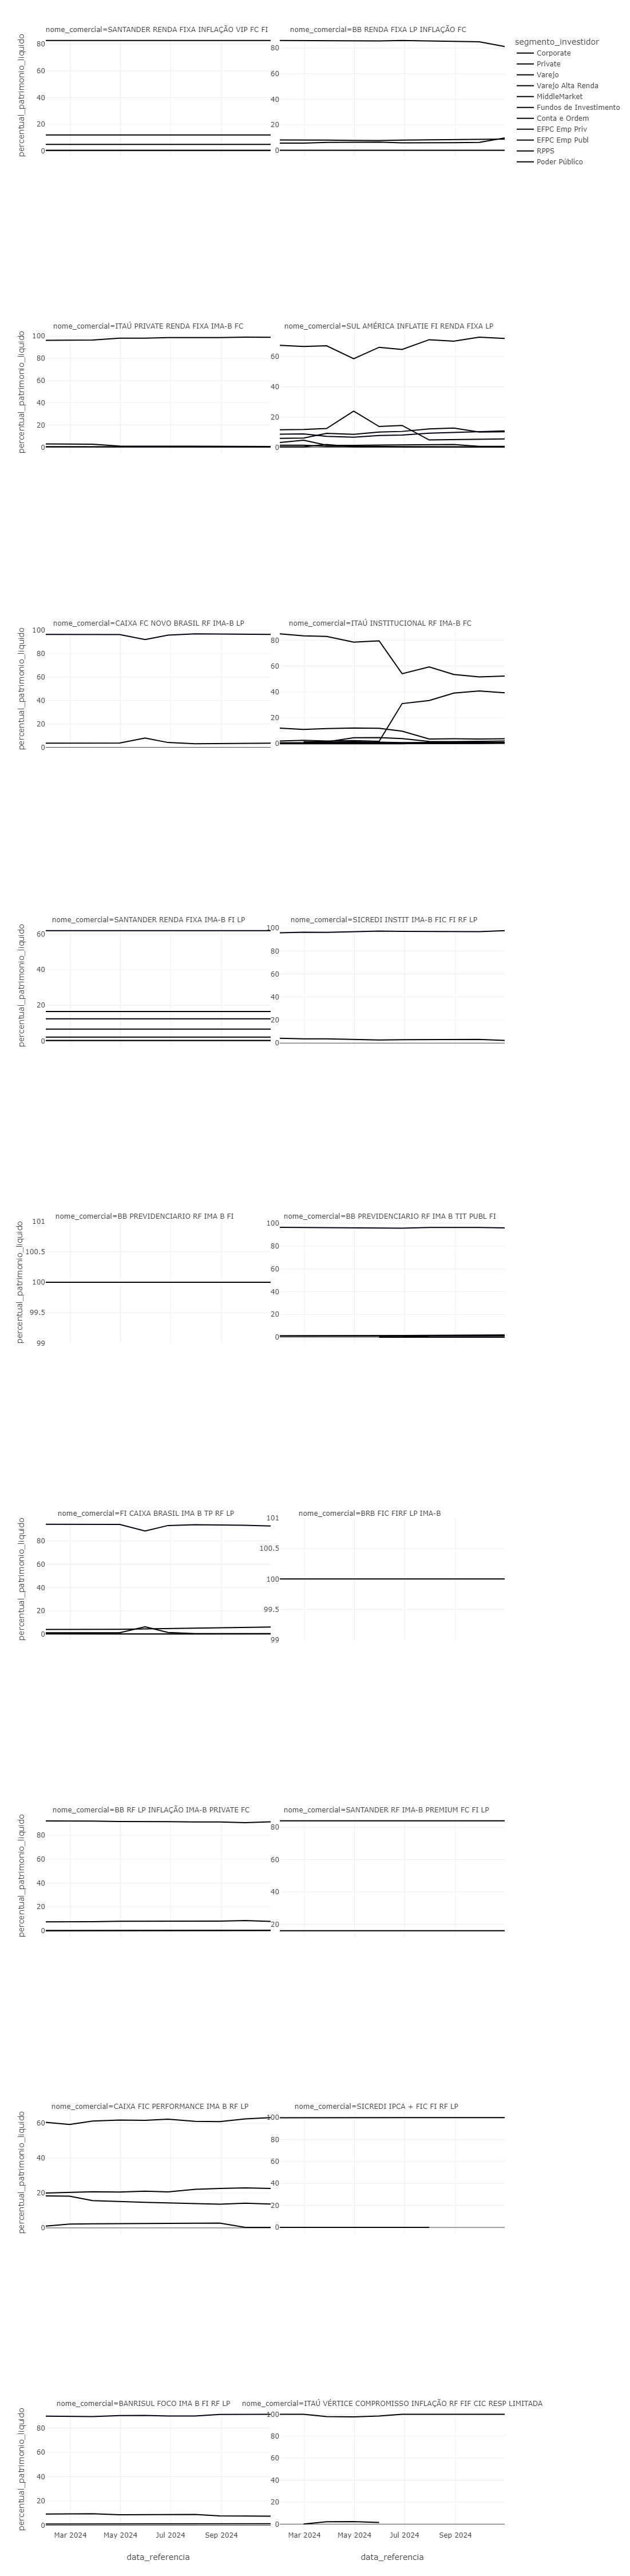

In [41]:
fig = plot_historico_area(df_hist_segmento, title='Historico PL por Segmento', facet='nome_comercial',color='segmento_investidor', value='percentual_patrimonio_liquido',x='data_referencia')
fig

C:\ProgramData\anaconda3\Lib\site-packages\_plotly_utils\basevalidators.py:106: FutureWarning:

The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result



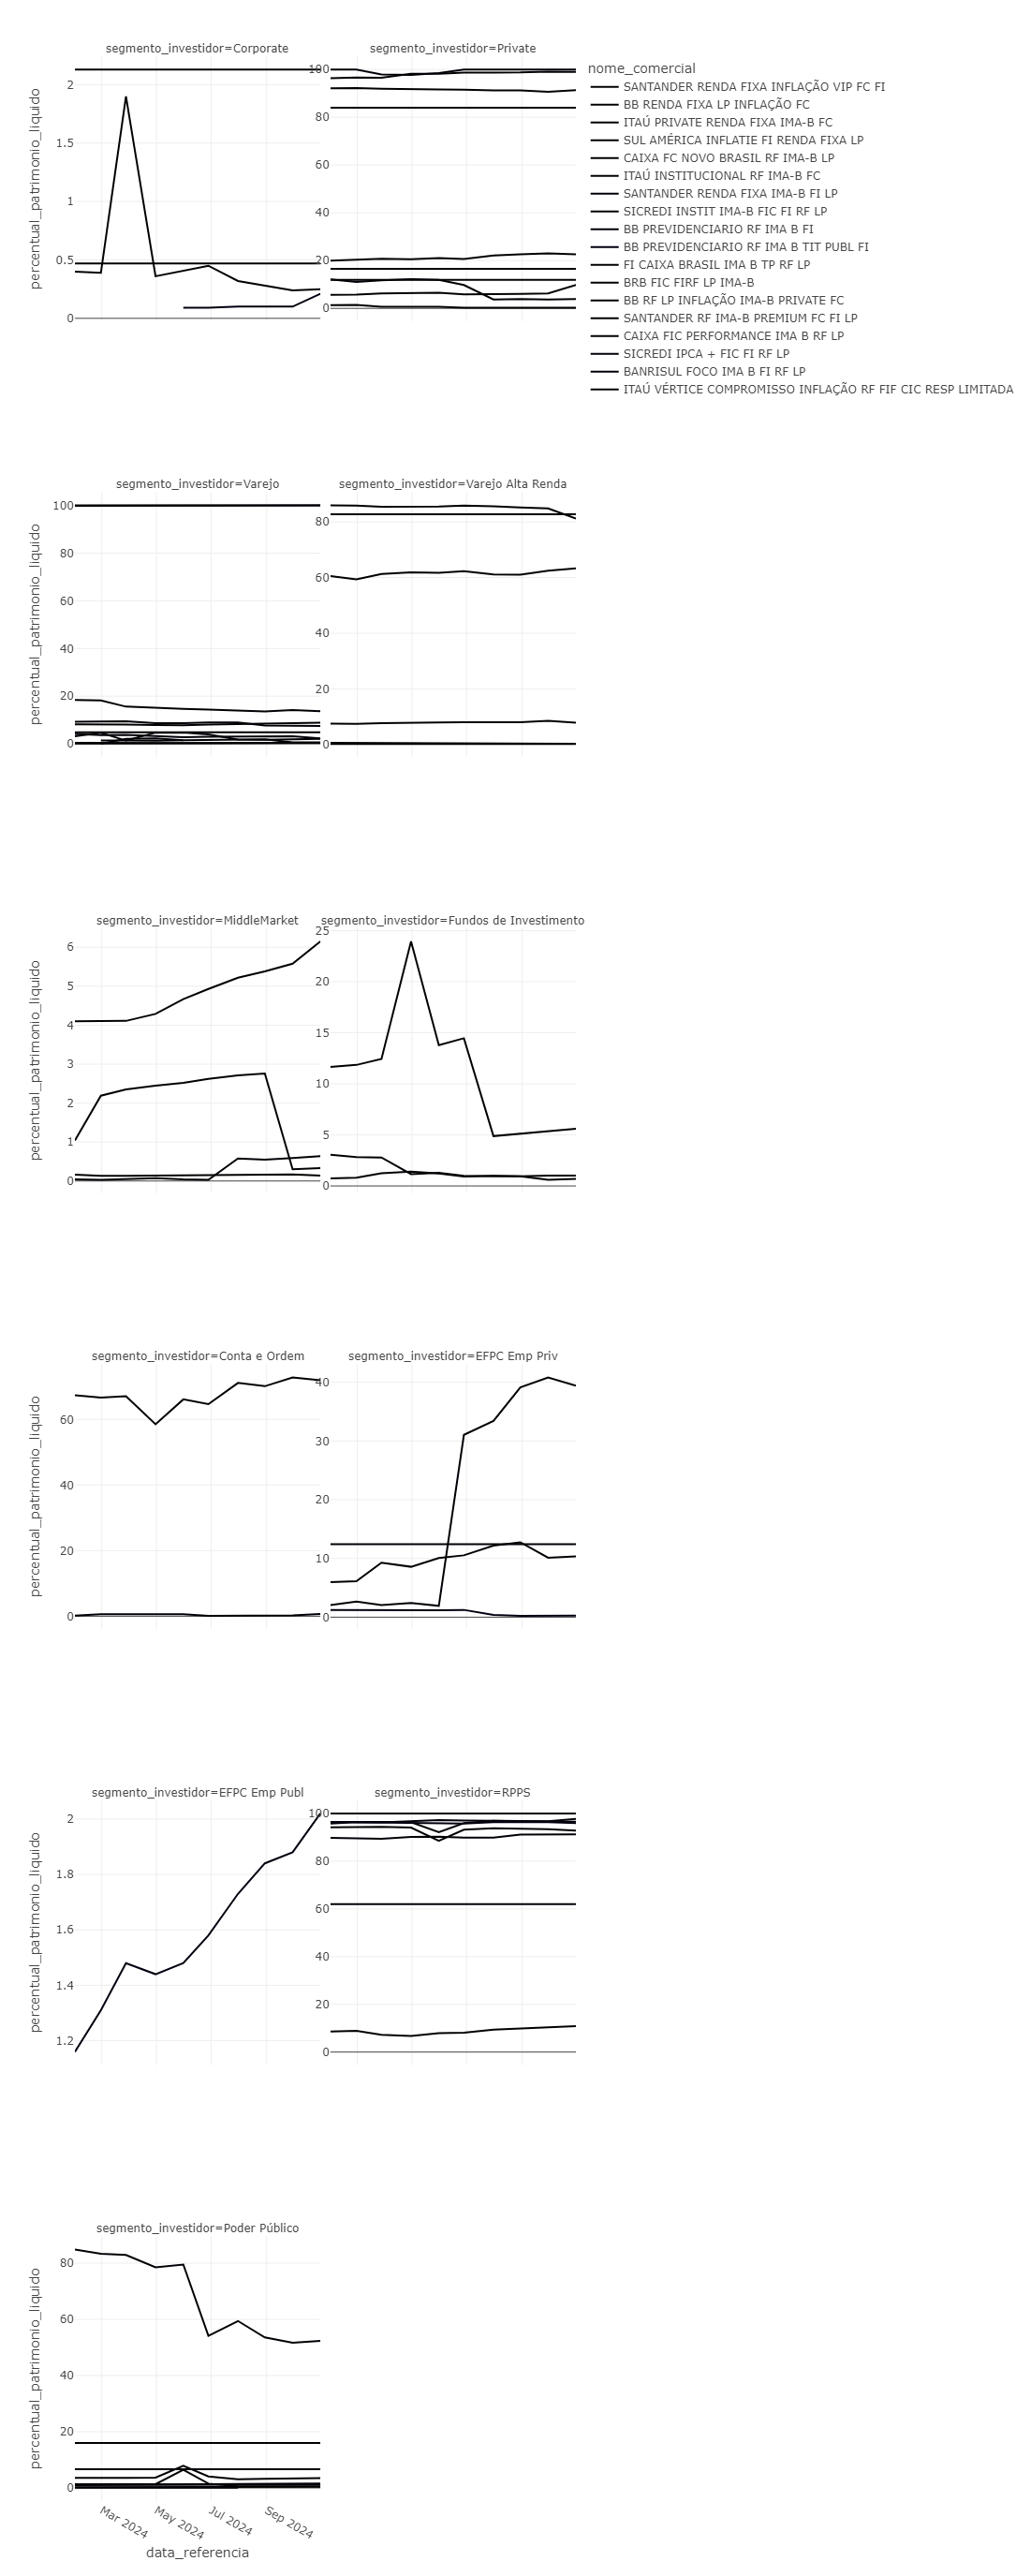

In [42]:
fig = plot_historico_area(df_hist_segmento, title='Historico PL por Segmento', facet='segmento_investidor',color='nome_comercial', value='percentual_patrimonio_liquido',x='data_referencia')
fig.show()

In [31]:
facet ='nome_comercial'
df_hist_segmento[facet].unique()

array(['SANTANDER RENDA FIXA INFLAÇÃO VIP FC FI ',
       'BB RENDA FIXA LP INFLAÇÃO FC            ',
       'ITAÚ PRIVATE RENDA FIXA IMA-B FC        ',
       'SUL AMÉRICA INFLATIE FI RENDA FIXA LP   ',
       'CAIXA FC NOVO BRASIL RF IMA-B LP        ',
       'ITAÚ INSTITUCIONAL RF IMA-B FC          ',
       'SANTANDER RENDA FIXA IMA-B FI LP        ',
       'SICREDI INSTIT IMA-B FIC FI RF LP       ',
       'BB PREVIDENCIARIO RF IMA B FI           ',
       'BB PREVIDENCIARIO RF IMA B TIT PUBL FI  ',
       'FI CAIXA BRASIL IMA B TP RF LP          ',
       'BRB FIC FIRF LP IMA-B                   ',
       'BB RF LP INFLAÇÃO IMA-B PRIVATE FC      ',
       'SANTANDER RF IMA-B PREMIUM FC FI LP     ',
       'CAIXA FIC PERFORMANCE IMA B RF LP       ',
       'SICREDI IPCA + FIC FI RF LP             ',
       'BANRISUL FOCO IMA B FI RF LP            ',
       'ITAÚ VÉRTICE COMPROMISSO INFLAÇÃO RF FIF CIC RESP LIMITADA'],
      dtype=object)

In [ ]:
fig = px.line(df_hist_segmento,
              y='percentual_patrimonio_liquido',
              x='data_referencia',
              facet_col_wrap=2,
              facet_col='nome_comercial',
              color='segmento_investidor')

fig.update_yaxes(matches=None)
fig.update_yaxes(showticklabels=True)
fig.update_layout(
    title="Distribuição do Patrimônio Líquido por Segmento de Investidor",
    xaxis_title="Data de Referência",
    yaxis_title="Percentual do Patrimônio Líquido",
    legend_title="Segmento de Investidor",
    template="plotly_white"
)
fig.show()

In [ ]:
import pandas as pd
import plotly.express as px

# Exemplo de DataFrame
data = {
    'segmento_investidor': ['Capitalização', 'Conta e Ordem', 'Corporate', 'Private'],
    'percentural_patrimonio_liquido': [0.0, 0.0, 0.0, 4.63],
    'percentual_patrimonio_liquido': [0.0, 0.0, 0.0, 4.63],
    'data_referencia': ['2024-10-31', '2024-10-31', '2024-10-31', '2024-10-31'],
    'nome_comercial': ['ITAÚ RF PRÉ LP FIF CIC RESP LIMITADA', 'ITAÚ RF PRÉ LP FIF CIC RESP LIMITADA', 'ITAÚ RF PRÉ LP FIF CIC RESP LIMITADA', 'ITAÚ RF PRÉ LP FIF CIC RESP LIMITADA']
}

df_hist_segmento2 = pd.DataFrame(data)

# Gerar o gráfico com Plotly Express
fig = px.line(df_hist_segmento,
              y='percentual_patrimonio_liquido',
              x='data_referencia',
              facet_col_wrap=2,
              facet_col='nome_comercial',
              color='segmento_investidor')

fig.update_yaxes(matches=None)
fig.update_yaxes(showticklabels=True)
fig.update_layout(
    title="Distribuição do Patrimônio Líquido por Segmento de Investidor",
    xaxis_title="Data de Referência",
    yaxis_title="Percentual do Patrimônio Líquido",
    legend_title="Segmento de Investidor",
    template="plotly_white"
)
fig.show()

In [ ]:
display(df_hist_segmento)

In [ ]:
display(df_hist_segmento2)